# 02. Inferential statistics: fade rate by operating condition (Chap 2)

**Lead:** Tiến Hưng · **Branch:** `tien-hung` · **WBS:** C2.1–C2.8 · **RQ1:** does the fade rate differ significantly by temperature, discharge current and load profile?

**Principle: the unit of observation is the BATTERY** (Go.md stage 3). Cycles within one battery are strongly autocorrelated (F9: lag-1 autocorrelation of the residuals is 0.40–0.93),
so using about 2,000 cycles as the sample would make p-values artificially small (pseudo-replication). Every test here uses `data/processed/battery_fade.csv`, one row per battery.

**Two response variables, every test is run on both** (robustness check):
- `fade_pct_per_100cyc`: slope of SOH against cycle over the **whole series**, in SOH percentage points lost per 100 cycles.
- `fade25_pct_per_100cyc`: the same slope using only the **first 25 cycles**, a window every battery has. Groups run very different numbers of cycles (28–197), so this variable compares them more fairly.

Significance level α = 0.05 for every test.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
ALPHA = 0.05
Y = {"fade": "fade_pct_per_100cyc", "fade25": "fade25_pct_per_100cyc"}

fade = pd.read_csv(DATA / "battery_fade.csv")


def condition(r):
    load = "CC" if r.profile == "constant_current" else "SQ"
    return f"{r.ambient_C:.0f}C/{load}/{r.I_level_A:.0f}A"


fade["condition"] = fade.apply(condition, axis=1)
print(f"{len(fade)} batteries in battery_fade.csv")
fade[["battery_id", "group", "tier", "condition", "discharge_cutoff_V", "n_used", Y["fade"], "n_used25", Y["fade25"],
      "cycles_to_soh80", "T_max_med"]].round(2)

23 batteries in battery_fade.csv


,battery_id,group,tier,condition,discharge_cutoff_V,n_used,fade_pct_per_100cyc,n_used25,fade25_pct_per_100cyc,cycles_to_soh80,T_max_med
0,B0005,G1,A,24C/CC/2A,2.7,167,20.97,25,4.23,102.0,40.07
1,B0006,G1,A,24C/CC/2A,2.5,166,24.70,25,25.52,61.0,40.33
2,B0007,G1,A,24C/CC/2A,2.2,167,17.00,25,5.22,126.0,40.59
3,B0018,G1,A,24C/CC/2A,2.5,132,20.96,25,32.75,77.0,37.75
4,B0025,G2,B,24C/SQ/4A,2.0,28,16.09,25,15.16,NaN,41.19
5,B0026,G2,B,24C/SQ/4A,2.2,25,10.49,22,9.37,NaN,40.57
6,B0027,G2,B,24C/SQ/4A,2.5,28,6.23,25,4.64,NaN,42.66
7,B0028,G2,B,24C/SQ/2A,2.7,28,14.63,25,13.33,NaN,31.76
8,B0029,G3,B,43C/CC/4A,2.0,39,30.93,25,29.86,NaN,59.99
9,B0030,G3,B,43C/CC/4A,2.2,39,30.38,25,30.64,NaN,62.52


## 1. Sample and condition groups

| Decision | Reason |
|---|---|
| Group by **condition** (ambient temperature, load profile, current level), not by experiment group G | B0036 belongs to G4 but runs CC 2 A at 24 °C, like G1. The table in Introduction_of_dataset.md section 8 also pools "G1 + B0036". |
| Exclude **B0054** from the main analysis | Tier N: 18.1% of its cycles are outliers and capacity alternates between two levels (Rec.md 2, #7–8). Go.md 3.2 explicitly lists G9 "without B0054". |
| Exclude **B0028** from the main analysis | Square wave with **2 A** amplitude (not 4 A as in the metadata); it is the only battery of this condition, so there is no within-group variance. |

That leaves **21 batteries in 6 condition groups**. Every number in this notebook uses this sample unless stated otherwise.
The battery-level regression of Quốc Đạt uses 23 batteries (it keeps B0054 and B0028); the report must state which sample each result uses.

In [2]:
EXCLUDE = {"B0054": "tier N (noisy)", "B0028": "only battery of its condition (SQ 2 A)"}
main = fade[~fade.battery_id.isin(EXCLUDE)].copy()
LEVELS = ["24C/CC/2A", "24C/CC/4A", "24C/SQ/4A", "43C/CC/4A", "4C/CC/1A", "4C/CC/2A"]
assert set(main.condition) == set(LEVELS) and len(main) == 21
groups = main.groupby("condition").agg(
    n=("battery_id", "size"), cells=("battery_id", lambda s: ", ".join(s)),
    fade_mean=(Y["fade"], "mean"), fade_sd=(Y["fade"], "std"),
    fade25_mean=(Y["fade25"], "mean"), fade25_sd=(Y["fade25"], "std"),
    T_max_med=("T_max_med", "mean")).loc[LEVELS]
groups.round(2)

,n,cells,fade_mean,fade_sd,fade25_mean,fade25_sd,T_max_med
condition,,,,,,,
24C/CC/2A,5,"B0005, B0006, B0007, B0018, B0036",17.90,7.26,14.41,13.69,39.02
24C/CC/4A,2,"B0033, B0034",8.27,2.03,20.10,7.74,55.57
24C/SQ/4A,3,"B0025, B0026, B0027",10.94,4.94,9.72,5.27,41.47
43C/CC/4A,4,"B0029, B0030, B0031, B0032",28.37,4.64,27.85,5.26,61.60
4C/CC/1A,4,"B0045, B0046, B0047, B0048",29.93,3.03,64.77,14.55,13.32
4C/CC/2A,3,"B0053, B0055, B0056",9.96,0.41,27.92,9.54,17.72


## 2. Confidence intervals (C2.1, Chap 2 pp. 4–19)

### 2.1 95% CI for the mean fade rate of each condition group
Each group has n = 2 to 5 batteries and σ is unknown, so the **t distribution with df = n − 1** is used (p. 8), not z:

$$\bar{x} \pm t_{n-1;\,0.025}\cdot \frac{s}{\sqrt{n}}$$

With n = 2, t(1; 0.025) = 12.706, so the interval is very wide: a quantitative measure of how limiting the number of batteries is.

In [3]:
ci_rows = []
for var, col in Y.items():
    for lv in LEVELS:
        x = main.loc[main.condition == lv, col]
        n, m, s = len(x), x.mean(), x.std(ddof=1)
        tcrit = stats.t.ppf(1 - ALPHA / 2, n - 1)
        half = tcrit * s / np.sqrt(n)
        ci_rows.append({"variable": col, "condition": lv, "n": n, "mean": m, "sd": s, "se": s / np.sqrt(n),
                        "df": n - 1, "t_crit": tcrit, "ci_low": m - half, "ci_high": m + half, "half_width": half})
ci_table = pd.DataFrame(ci_rows)
ci_table.round(3)

,variable,condition,n,mean,sd,se,df,t_crit,ci_low,ci_high,half_width
0,fade_pct_per_100cyc,24C/CC/2A,5,17.897,7.258,3.246,4,2.776,8.884,26.909,9.013
1,fade_pct_per_100cyc,24C/CC/4A,2,8.271,2.028,1.434,1,12.706,-9.953,26.496,18.224
2,fade_pct_per_100cyc,24C/SQ/4A,3,10.938,4.941,2.852,2,4.303,-1.335,23.211,12.273
3,fade_pct_per_100cyc,43C/CC/4A,4,28.373,4.638,2.319,3,3.182,20.993,35.753,7.380
4,fade_pct_per_100cyc,4C/CC/1A,4,29.934,3.033,1.516,3,3.182,25.109,34.760,4.825
5,fade_pct_per_100cyc,4C/CC/2A,3,9.956,0.412,0.238,2,4.303,8.933,10.979,1.023
6,fade25_pct_per_100cyc,24C/CC/2A,5,14.412,13.688,6.121,4,2.776,-2.584,31.407,16.996
7,fade25_pct_per_100cyc,24C/CC/4A,2,20.102,7.745,5.476,1,12.706,-49.482,89.686,69.584
8,fade25_pct_per_100cyc,24C/SQ/4A,3,9.723,5.266,3.040,2,4.303,-3.358,22.804,13.081
9,fade25_pct_per_100cyc,43C/CC/4A,4,27.847,5.264,2.632,3,3.182,19.471,36.223,8.376


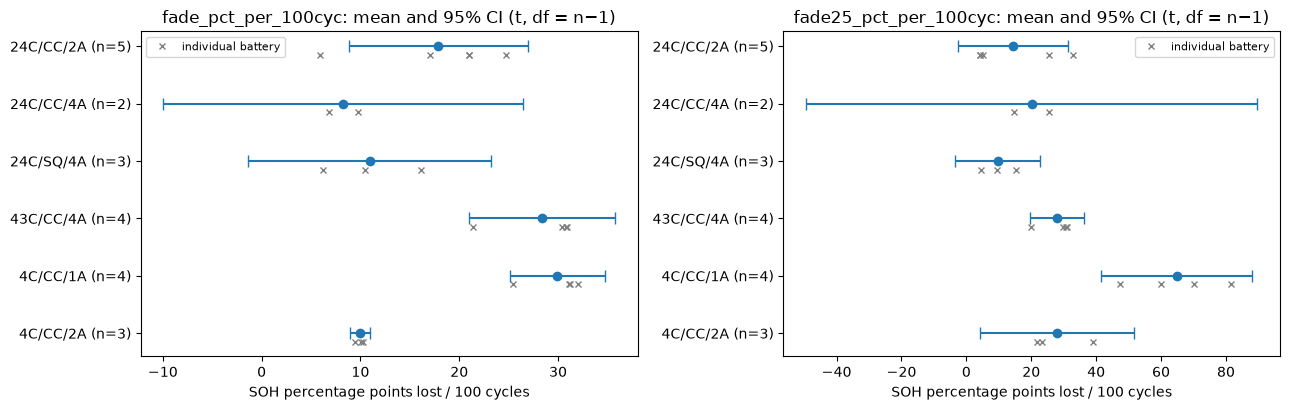

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, (var, col) in zip(axes, Y.items()):
    t = ci_table[ci_table.variable == col].reset_index(drop=True)
    ax.errorbar(t["mean"], range(len(t)), xerr=t.half_width, fmt="o", capsize=4)
    pts = main[[col, "condition"]]
    ax.plot(pts[col], [LEVELS.index(c) + 0.15 for c in pts.condition], "x", color="gray", ms=5, label="individual battery")
    ax.set_yticks(range(len(t)), [f"{c} (n={n})" for c, n in zip(t.condition, t.n)])
    ax.invert_yaxis()
    ax.set_xlabel("SOH percentage points lost / 100 cycles")
    ax.set_title(f"{col}: mean and 95% CI (t, df = n−1)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "inf_01_ci_by_condition.png", dpi=150)
plt.show()

### 2.2 CI for a proportion: share of discharges whose capacity rose versus the previous discharge (pp. 16–19)

This share measures how common capacity regeneration is (F5). It uses tier A and B batteries, drops `cap_outlier` and `break_in`, and only compares two consecutive discharges **within the same battery**.
The sample is large (np and n(1−p) both > 5), so z is used (p. 17):

$$\hat{p} \pm z_{0.025}\sqrt{\hat{p}(1-\hat{p})/n}$$

**Caveat:** the z formula assumes independent discharges, but cycles within a battery are not independent (F9). This interval is therefore **too narrow**.
To show by how much, a second interval uses the battery as the unit: compute the share for each battery, then a t CI for the mean of those shares.

In [5]:
clean = pd.read_csv(DATA / "cycles_clean.csv", usecols=["battery_id", "cycle_valid", "soh", "tier", "cap_outlier", "break_in"])
ab = clean[clean.tier.isin(["A", "B"]) & ~clean.cap_outlier & ~clean.break_in].sort_values(["battery_id", "cycle_valid"])
ab = ab.assign(up=ab.groupby("battery_id").soh.diff() > 0, has_prev=ab.groupby("battery_id").soh.shift().notna())
pairs = ab[ab.has_prev]
n, k = len(pairs), int(pairs.up.sum())
p_hat = k / n
z = stats.norm.ppf(1 - ALPHA / 2)
half = z * np.sqrt(p_hat * (1 - p_hat) / n)
per_cell = pairs.groupby("battery_id").up.mean()
tc = stats.t.ppf(1 - ALPHA / 2, len(per_cell) - 1)
half_cell = tc * per_cell.std(ddof=1) / np.sqrt(len(per_cell))
prop_table = pd.DataFrame([
    {"method": "z, unit = discharge", "n": n, "k_up": k, "estimate": p_hat, "ci_low": p_hat - half, "ci_high": p_hat + half,
     "check_np_ge_5": min(k, n - k) >= 5},
    {"method": "t, unit = battery (mean of per-battery shares)", "n": len(per_cell), "k_up": np.nan,
     "estimate": per_cell.mean(), "ci_low": per_cell.mean() - half_cell, "ci_high": per_cell.mean() + half_cell,
     "check_np_ge_5": np.nan}])
print(f"{ab.battery_id.nunique()} tier A/B batteries")
prop_table.round(4)

22 tier A/B batteries


,method,n,k_up,estimate,ci_low,ci_high,check_np_ge_5
0,"z, unit = discharge",1966,562.0,0.2859,0.2659,0.3058,True
1,"t, unit = battery (mean of per-battery shares)",22,NaN,0.2670,0.2229,0.3111,NaN


## 3. Two-group comparisons that differ in one factor only (C2.2–C2.3, Chap 2 pp. 38–53, 64)

| # | Comparison | Group 1 | Group 2 | H0 / Ha |
|---|---|---|---|---|
| T1 | Temperature at CC 4 A | 43 °C (G3, n = 4) | 24 °C (B0033, B0034, n = 2) | H0: μ43 ≤ μ24; Ha: μ43 > μ24 (**one-sided**) |
| T2 | Temperature at CC 2 A | 24 °C (G1 + B0036, n = 5) | 4 °C (G9 without B0054, n = 3) | H0: μ24 = μ4; Ha: ≠ |
| T3 | Discharge current at 4 °C | CC 1 A (G7, n = 4) | CC 2 A (G9 without B0054, n = 3) | H0: μ1A = μ2A; Ha: ≠ |
| T4 | Load profile at 24 °C / 4 A | square wave (B0025–27, n = 3) | CC (B0033, B0034, n = 2) | H0: μSQ = μCC; Ha: ≠ |

**Why T1 is one-sided:** the hypothesis was stated **before looking at the data**, from a known mechanism: high temperature accelerates side reactions (SEI growth follows Arrhenius),
so only the direction "43 °C fades faster" is of interest. The other three pairs have no direction that theory makes certain, so they are two-sided.

**Procedure for each pair and each variable:**
1. **F-test** of the variance ratio (p. 51), H0: σ₁² = σ₂², two-sided. **Levene** (p. 64, `center="median"`) is also run for comparison.
2. If the F-test does not reject H0 (p > 0.05), use the **pooled t-test**, df = n₁ + n₂ − 2 (p. 40). If it rejects, use the **Welch t-test** (Welch–Satterthwaite df; beyond the slides).
3. Report T, df, critical value, p-value, decision, and the 95% CI for the difference μ₁ − μ₂.
4. **Sensitivity check:** column `p_Welch` gives the Welch p-value for every pair. With n = 2 in one group (T1, T4) the F-test and Levene have almost no power, so
   "not rejecting equal variances" does not show that the variances are equal; `p_Welch` shows whether the decision depends on that choice.

**Why t and not z:** each group has only 2–5 batteries and σ is unknown and estimated by s. The t distribution has heavier tails to account for the error in s (p. 8, p. 40).

In [6]:
G1_ONLY = ["B0005", "B0006", "B0007", "B0018"]
PAIRS = {
    "T1": ("43C/CC/4A", "24C/CC/4A", "greater", "Temperature at CC 4 A: 43 °C vs 24 °C"),
    "T2": ("24C/CC/2A", "4C/CC/2A", "two-sided", "Temperature at CC 2 A: 24 °C vs 4 °C"),
    "T3": ("4C/CC/1A", "4C/CC/2A", "two-sided", "Discharge current at 4 °C: 1 A vs 2 A"),
    "T4": ("24C/SQ/4A", "24C/CC/4A", "two-sided", "Load profile at 24 °C/4 A: square wave vs CC"),
}


def f_test(a, b):
    # Two-sided F-test of equal variances (Chap 2 p. 51): F = s1²/s2², df = (n1-1, n2-1)
    F = np.var(a, ddof=1) / np.var(b, ddof=1)
    d1, d2 = len(a) - 1, len(b) - 1
    p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
    return F, d1, d2, min(p, 1.0)


def two_sample(name, a, b, alt, label, col, note=""):
    a, b = np.asarray(a, float), np.asarray(b, float)
    F, d1, d2, pF = f_test(a, b)
    lev = stats.levene(a, b, center="median")
    pooled = pF > ALPHA
    res = stats.ttest_ind(a, b, equal_var=pooled, alternative=alt)
    welch = stats.ttest_ind(a, b, equal_var=False, alternative=alt)       # sensitivity check
    df = res.df
    tcrit = stats.t.ppf(1 - ALPHA, df) if alt == "greater" else stats.t.ppf(1 - ALPHA / 2, df)
    if pooled:
        sp2 = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
        se = np.sqrt(sp2 * (1 / len(a) + 1 / len(b)))
    else:
        se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    t2 = stats.t.ppf(1 - ALPHA / 2, df)
    diff = a.mean() - b.mean()
    return {"test": name + note, "comparison": label, "variable": col, "n1": len(a), "n2": len(b),
            "mean1": a.mean(), "mean2": b.mean(), "sd1": a.std(ddof=1), "sd2": b.std(ddof=1),
            "F": F, "F_df": f"({d1},{d2})", "p_F": pF, "p_Levene": lev.pvalue,
            "t_test": "pooled" if pooled else "Welch", "Ha": alt, "T": res.statistic, "df": df, "t_crit": tcrit,
            "p": res.pvalue, "reject_H0": res.pvalue < ALPHA,
            "diff": diff, "diff_ci_low": diff - t2 * se, "diff_ci_high": diff + t2 * se,
            "p_Welch": welch.pvalue, "reject_H0_Welch": welch.pvalue < ALPHA}


t_rows = []
for col in Y.values():
    for name, (g1, g2, alt, label) in PAIRS.items():
        a = main.loc[main.condition == g1, col]
        b = main.loc[main.condition == g2, col]
        t_rows.append(two_sample(name, a, b, alt, label, col))
    # T2 as in Go.md: G1 only (n = 4), without B0036
    a = main.loc[main.battery_id.isin(G1_ONLY), col]
    b = main.loc[main.condition == "4C/CC/2A", col]
    t_rows.append(two_sample("T2", a, b, "two-sided", "Temperature at CC 2 A: G1 only vs 4 °C", col, note="b (G1 only)"))
t_table = pd.DataFrame(t_rows)
t_table.round(4)

,test,comparison,variable,n1,n2,mean1,mean2,sd1,sd2,F,F_df,p_F,p_Levene,t_test,Ha,T,df,t_crit,p,reject_H0,diff,diff_ci_low,diff_ci_high,p_Welch,reject_H0_Welch
0,T1,Temperature at CC 4 A: 43 °C vs 24 °C,fade_pct_per_100cyc,4,2,28.3730,8.2715,4.6377,2.0284,5.2277,"(3,1)",0.6172,0.7716,pooled,greater,5.6033,4.0000,2.1318,0.0025,True,20.1016,10.1411,30.0620,0.0009,True
1,T2,Temperature at CC 2 A: 24 °C vs 4 °C,fade_pct_per_100cyc,5,3,17.8967,9.9560,7.2584,0.4119,310.5468,"(4,2)",0.0064,0.2892,Welch,two-sided,2.4397,4.0428,2.7649,0.0706,False,7.9407,-1.0583,16.9398,0.0706,False
2,T3,Discharge current at 4 °C: 1 A vs 2 A,fade_pct_per_100cyc,4,3,29.9344,9.9560,3.0325,0.4119,54.2068,"(3,2)",0.0363,0.4294,Welch,two-sided,13.0169,3.1465,3.1002,0.0008,True,19.9784,15.2202,24.7366,0.0008,True
3,T4,Load profile at 24 °C/4 A: square wave vs CC,fade_pct_per_100cyc,3,2,10.9378,8.2715,4.9405,2.0284,5.9327,"(2,1)",0.5576,0.4580,pooled,two-sided,0.6953,3.0000,3.1824,0.5369,False,2.6663,-9.5368,14.8694,0.4692,False
4,T2b (G1 only),Temperature at CC 2 A: G1 only vs 4 °C,fade_pct_per_100cyc,4,3,20.9056,9.9560,3.1446,0.4119,58.2886,"(3,2)",0.0338,0.2642,Welch,two-sided,6.8857,3.1364,3.1056,0.0054,True,10.9497,6.0112,15.8882,0.0054,True
5,T1,Temperature at CC 4 A: 43 °C vs 24 °C,fade25_pct_per_100cyc,4,2,27.8468,20.1019,5.2637,7.7447,0.4619,"(3,1)",0.4752,0.5260,pooled,greater,1.4952,4.0000,2.1318,0.1046,False,7.7449,-6.6369,22.1266,0.1829,False
6,T2,Temperature at CC 2 A: 24 °C vs 4 °C,fade25_pct_per_100cyc,5,3,14.4117,27.9244,13.6879,9.5413,2.0580,"(4,2)",0.7054,0.6415,pooled,two-sided,-1.4850,6.0000,2.4469,0.1881,False,-13.5127,-35.7783,8.7530,0.1548,False
7,T3,Discharge current at 4 °C: 1 A vs 2 A,fade25_pct_per_100cyc,4,3,64.7681,27.9244,14.5533,9.5413,2.3265,"(3,2)",0.6295,0.4093,pooled,two-sided,3.7727,5.0000,2.5706,0.0130,True,36.8438,11.7399,61.9476,0.0101,True
8,T4,Load profile at 24 °C/4 A: square wave vs CC,fade25_pct_per_100cyc,3,2,9.7227,20.1019,5.2658,7.7447,0.4623,"(2,1)",0.5583,0.4538,pooled,two-sided,-1.8329,3.0000,3.1824,0.1642,False,-10.3792,-28.4004,7.6420,0.2661,False
9,T2b (G1 only),Temperature at CC 2 A: G1 only vs 4 °C,fade25_pct_per_100cyc,4,3,16.9308,27.9244,14.4051,9.5413,2.2794,"(3,2)",0.6389,0.2257,pooled,two-sided,-1.1347,5.0000,2.5706,0.3080,False,-10.9936,-35.8990,13.9118,0.2797,False


**Reading the table:** `t_test` says whether pooled or Welch was used, following the F-test. `diff` is μ₁ − μ₂ (percentage points / 100 cycles), with a two-sided 95% CI.
For T1 (one-sided), H0 is rejected when T > `t_crit` = t(df; 0.05). `T2b` uses G1 only, as in Go.md 3.2, to check the effect of pooling B0036.
`reject_H0_Welch` equals `reject_H0` in every row, so no decision depends on the pooled/Welch choice.

## 4. One-way ANOVA by condition group and Tukey HSD (C2.4, Chap 2 pp. 72–89)

The factor is the **condition group**, 6 levels, 21 batteries. H0: μ₁ = … = μ₆; Ha: at least one mean differs.
Assumptions (p. 75): independent observations (true, since each observation is a battery), equal variances (Levene), normal residuals (QQ-plot and Shapiro-Wilk).
If normality or equal variances is violated, **Kruskal-Wallis** (non-parametric, beyond the slides) is run as a cross-check.

⚠ Interpret the factor as "condition group", not "temperature", because temperature is confounded with discharge current and load profile.

In [7]:
def anova_table(df, col):
    y = df[col]
    grand = y.mean()
    by = df.groupby("condition")[col]
    ssb = (by.size() * (by.mean() - grand) ** 2).sum()
    ssw = ((y - by.transform("mean")) ** 2).sum()
    k, N = by.ngroups, len(y)
    msb, msw = ssb / (k - 1), ssw / (N - k)
    F = msb / msw
    return pd.DataFrame({"Source": ["Between (condition)", "Within (error)", "Total"],
                         "SS": [ssb, ssw, ssb + ssw], "df": [k - 1, N - k, N - 1], "MS": [msb, msw, np.nan],
                         "F": [F, np.nan, np.nan], "F_crit": [stats.f.ppf(1 - ALPHA, k - 1, N - k), np.nan, np.nan],
                         "p": [stats.f.sf(F, k - 1, N - k), np.nan, np.nan]})


anova_out, assumption_rows = {}, []
for col in Y.values():
    samples = [main.loc[main.condition == lv, col].to_numpy() for lv in LEVELS]
    tab = anova_table(main, col)
    fo = stats.f_oneway(*samples)
    assert np.isclose(fo.statistic, tab.F[0]) and np.isclose(fo.pvalue, tab.p[0])   # hand-built table matches scipy
    resid = main[col] - main.groupby("condition")[col].transform("mean")
    lev = stats.levene(*samples, center="median")
    sh = stats.shapiro(resid)
    kw = stats.kruskal(*samples)
    anova_out[col] = (tab, resid)
    assumption_rows.append({"variable": col, "F": fo.statistic, "p_ANOVA": fo.pvalue, "p_Levene": lev.pvalue,
                            "p_Shapiro_resid": sh.pvalue, "H_Kruskal": kw.statistic, "p_Kruskal": kw.pvalue})
    print(f"\nANOVA table: {col}")
    print(tab.round(4).to_string(index=False))
assumptions = pd.DataFrame(assumption_rows)
assumptions.round(4)


ANOVA table: fade_pct_per_100cyc
             Source        SS  df       MS       F  F_crit      p
Between (condition) 1505.9149   5 301.1830 12.6858  2.9013 0.0001
     Within (error)  356.1248  15  23.7417     NaN     NaN    NaN
              Total 1862.0398  20      NaN     NaN     NaN    NaN

ANOVA table: fade25_pct_per_100cyc
             Source        SS  df        MS       F  F_crit      p
Between (condition) 7455.0437   5 1491.0087 12.6682  2.9013 0.0001
     Within (error) 1765.4614  15  117.6974     NaN     NaN    NaN
              Total 9220.5052  20       NaN     NaN     NaN    NaN


,variable,F,p_ANOVA,p_Levene,p_Shapiro_resid,H_Kruskal,p_Kruskal
0,fade_pct_per_100cyc,12.6858,0.0001,0.7626,0.0415,15.5511,0.0082
1,fade25_pct_per_100cyc,12.6682,0.0001,0.6862,0.6124,13.1221,0.0223


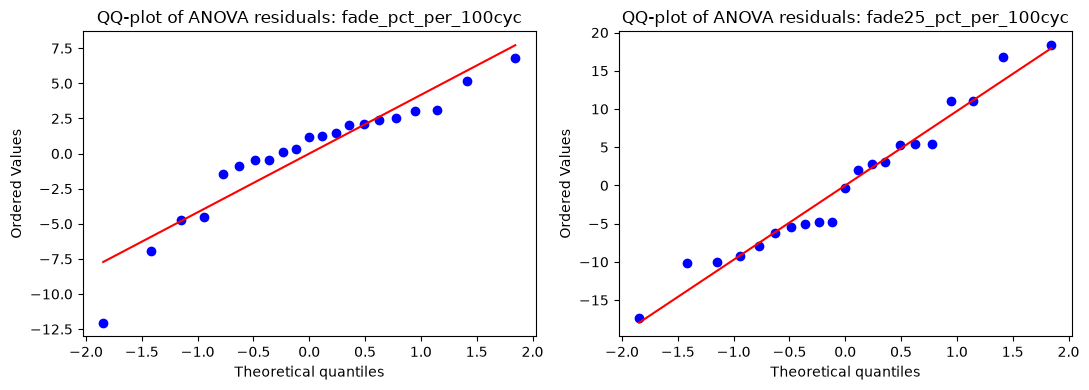

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, Y.values()):
    stats.probplot(anova_out[col][1], dist="norm", plot=ax)
    ax.set_title(f"QQ-plot of ANOVA residuals: {col}")
fig.tight_layout()
fig.savefig(FIG / "inf_02_anova_qq.png", dpi=150)
plt.show()

In [9]:
tukey_rows = []
for col in Y.values():
    tk = pairwise_tukeyhsd(main[col], main.condition, alpha=ALPHA)
    t = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])
    t.insert(0, "variable", col)
    tukey_rows.append(t)
tukey = pd.concat(tukey_rows, ignore_index=True)
print("Tukey HSD (meandiff = group2 − group1). Interpret only when the ANOVA of that variable has p < 0.05.")
tukey[tukey.reject]

Tukey HSD (meandiff = group2 − group1). Interpret only when the ANOVA of that variable has p < 0.05.


,variable,group1,group2,meandiff,p-adj,lower,upper,reject
3,fade_pct_per_100cyc,24C/CC/2A,4C/CC/1A,12.0376,0.0221,1.4181,22.6572,True
6,fade_pct_per_100cyc,24C/CC/4A,43C/CC/4A,20.1016,0.0028,6.3917,33.8114,True
7,fade_pct_per_100cyc,24C/CC/4A,4C/CC/1A,21.6629,0.0014,7.9531,35.3727,True
9,fade_pct_per_100cyc,24C/SQ/4A,43C/CC/4A,17.4353,0.0033,5.3443,29.5262,True
10,fade_pct_per_100cyc,24C/SQ/4A,4C/CC/1A,18.9966,0.0015,6.9057,31.0875,True
13,fade_pct_per_100cyc,43C/CC/4A,4C/CC/2A,-18.4171,0.0020,-30.5080,-6.3262,True
14,fade_pct_per_100cyc,4C/CC/1A,4C/CC/2A,-19.9784,0.0009,-32.0693,-7.8875,True
18,fade25_pct_per_100cyc,24C/CC/2A,4C/CC/1A,50.3564,0.0001,26.7116,74.0012,True
22,fade25_pct_per_100cyc,24C/CC/4A,4C/CC/1A,44.6662,0.0029,14.1410,75.1915,True
25,fade25_pct_per_100cyc,24C/SQ/4A,4C/CC/1A,55.0454,0.0001,28.1247,81.9662,True


In [10]:
tukey

,variable,group1,group2,meandiff,p-adj,lower,upper,reject
0,fade_pct_per_100cyc,24C/CC/2A,24C/CC/4A,-9.6252,0.2305,-22.8702,3.6197,False
1,fade_pct_per_100cyc,24C/CC/2A,24C/SQ/4A,-6.9589,0.4091,-18.5201,4.6022,False
2,fade_pct_per_100cyc,24C/CC/2A,43C/CC/4A,10.4763,0.0542,-0.1432,21.0959,False
3,fade_pct_per_100cyc,24C/CC/2A,4C/CC/1A,12.0376,0.0221,1.4181,22.6572,True
4,fade_pct_per_100cyc,24C/CC/2A,4C/CC/2A,-7.9407,0.2800,-19.5019,3.6204,False
5,fade_pct_per_100cyc,24C/CC/4A,24C/SQ/4A,2.6663,0.9895,-11.7851,17.1177,False
6,fade_pct_per_100cyc,24C/CC/4A,43C/CC/4A,20.1016,0.0028,6.3917,33.8114,True
7,fade_pct_per_100cyc,24C/CC/4A,4C/CC/1A,21.6629,0.0014,7.9531,35.3727,True
8,fade_pct_per_100cyc,24C/CC/4A,4C/CC/2A,1.6845,0.9988,-12.7669,16.1359,False
9,fade_pct_per_100cyc,24C/SQ/4A,43C/CC/4A,17.4353,0.0033,5.3443,29.5262,True


## 5. Why a two-way ANOVA is not possible (C2.5, Chap 2 p. 90)

A two-way ANOVA with factors temperature × discharge current needs **observations in every cell** (the slides use a balanced design, the same sample size in every cell) and at least
2 observations per cell to estimate the interaction. The battery counts per cell below (CC only, main sample) show this condition is not met.

In [11]:
cc = main[main.condition.str.contains("/CC/")]
cells = pd.crosstab(cc.ambient_C, cc.I_level_A).reindex(index=[4.0, 24.0, 43.0], columns=[1.0, 2.0, 4.0], fill_value=0)
cells.index = [f"{t:.0f} °C" for t in cells.index]
cells.columns = [f"{i:.0f} A" for i in cells.columns]
print(f"Empty cells: {(cells == 0).sum().sum()} / {cells.size}")
cells

Empty cells: 4 / 9


,1 A,2 A,4 A
4 °C,4,3,0
24 °C,0,5,2
43 °C,0,0,4


**Explanation (for Report §4):** 4 of the 9 temperature × current cells are empty: no battery runs 1 A at 24 °C or 43 °C, 2 A at 43 °C, or 4 A at 4 °C.
The non-empty cells are also unbalanced (2 to 5 batteries). The NASA experiment is not a full factorial design: each temperature is paired with only a few current levels.
Therefore:
- the temperature × current interaction cannot be estimated, because an interaction needs every combination of levels;
- the main effect of temperature is confounded with discharge current (43 °C only has 4 A, 4 °C only has 1 A and 2 A).

The team therefore uses a **one-way ANOVA by condition group** (section 4) and **pairs that differ in one factor only** (T1–T4, section 3) to separate the factors.

## 6. Chi-square: temperature group × "SOH < 0.9 within the first W cycles" (C2.6, Chap 2 pp. 56–63)

Contingency table at **battery level**. Outcome: whether the battery has at least one discharge with SOH < 0.9 within `cycle_valid` ≤ W (dropping `cap_outlier` and `break_in`).
H0: temperature group and outcome are independent. Expected frequencies E_ij = (row total × column total) / n as on pp. 59–60.

**Choice of W.** Go.md 3.5 chooses W = 40 because "this is the shortest series of G3, so every battery is fully observed". The data shows this reason **does not hold**:
G3 (B0029–B0032) has only 39 valid discharges (`cycle_valid` 1–39), and the square-wave batteries of G2 (B0025–B0027) only reach `cycle_valid` 28. With W = 40 these batteries are
observed for fewer cycles than the others, so they can be classed "no" only because they have not run long enough. Therefore:
- **Main version: W = 25**, a window every battery has (the same window as `fade25_pct_per_100cyc`), 21 batteries.
- **Check version: W = 39**, closest to the intent of Go.md, only on batteries with at least 39 cycles (G2 dropped).

⚠ This change of W is a **proposal pending the Leader's sign-off** (a dated change note in Rec.md and Go.md 3.5). The two versions reach different decisions,
so the report must present **both**, not pick one.

When some E_ij < 5 the χ² approximation is unreliable (p. 61). Fisher's exact test only applies directly to 2 × 2 tables, so a **permutation test** (beyond the slides) is added:
row and column totals are kept, the temperature labels are shuffled among batteries 20,000 times, and p = the share of shuffles with χ² ≥ the observed χ². Seed = 42 for reproducibility.

In [12]:
REPS = 20000
last_valid = clean[~clean.cap_outlier & ~clean.break_in].groupby("battery_id").cycle_valid.max()


def chi2_stat(l, o):
    tab = pd.crosstab(l, o).to_numpy()
    return stats.chi2_contingency(tab, correction=False)[0] if tab.shape[1] == 2 else 0.0


def chi_square(window, cells):
    early = clean[clean.battery_id.isin(cells) & ~clean.cap_outlier & ~clean.break_in & (clean.cycle_valid <= window)]
    reach = early.groupby("battery_id").cycle_valid.max()
    below = early.groupby("battery_id").soh.min().lt(0.9).rename("below")
    df = main.set_index("battery_id").loc[list(cells), ["ambient_C"]].join(below)
    obs = pd.crosstab(df.ambient_C, df.below).reindex(columns=[False, True], fill_value=0)
    obs.index = [f"{t:.0f} °C" for t in obs.index]
    obs.columns = ["no", "yes (SOH < 0.9)"]
    chi2, p_chi, dof, exp = stats.chi2_contingency(obs.to_numpy(), correction=False)
    exp = pd.DataFrame(exp, index=obs.index, columns=obs.columns)
    rng = np.random.default_rng(42)
    lab, out = df.ambient_C.to_numpy(), df.below.to_numpy()
    perm = np.array([chi2_stat(rng.permutation(lab), out) for _ in range(REPS)])
    p_perm = (np.sum(perm >= chi2 - 1e-12) + 1) / (REPS + 1)
    print(f"=== W = {window}, {len(df)} batteries; smallest (over batteries) of the largest cycle_valid inside the window = {reach.min()}")
    print("Observed table O_ij"); print(obs.to_string())
    print("Expected table E_ij"); print(exp.round(2).to_string())
    print(f"χ² = {chi2:.4f}, df = {dof}, χ²_crit = {stats.chi2.ppf(1 - ALPHA, dof):.4f}, p (χ²) = {p_chi:.4f}, "
          f"p (permutation) = {p_perm:.4f}; cells with E_ij < 5: {int((exp < 5).sum().sum())}/{exp.size}\n")
    return {"window": window, "n_cells": len(df), "chi2": chi2, "df": dof, "p_chi2": p_chi, "p_perm": p_perm,
            "n_cells_E_lt_5": int((exp < 5).sum().sum())}


chi_main = chi_square(25, main.battery_id)
cells39 = [b for b in main.battery_id if last_valid[b] >= 39]
print("Dropped from the W = 39 version (fewer than 39 cycles):", sorted(set(main.battery_id) - set(cells39)))
chi_39 = chi_square(39, cells39)
chi_table = pd.DataFrame([chi_main, chi_39])
chi_table.round(4)

=== W = 25, 21 batteries; smallest (over batteries) of the largest cycle_valid inside the window = 25
Observed table O_ij
       no  yes (SOH < 0.9)
4 °C    1                6
24 °C   9                1
43 °C   4                0
Expected table E_ij
         no  yes (SOH < 0.9)
4 °C   4.67             2.33
24 °C  6.67             3.33
43 °C  2.67             1.33
χ² = 13.0929, df = 2, χ²_crit = 5.9915, p (χ²) = 0.0014, p (permutation) = 0.0014; cells with E_ij < 5: 5/6

Dropped from the W = 39 version (fewer than 39 cycles): ['B0025', 'B0026', 'B0027']


=== W = 39, 18 batteries; smallest (over batteries) of the largest cycle_valid inside the window = 39
Observed table O_ij
       no  yes (SOH < 0.9)
4 °C    1                6
24 °C   4                3
43 °C   1                3
Expected table E_ij
         no  yes (SOH < 0.9)
4 °C   2.33             4.67
24 °C  2.33             4.67
43 °C  1.33             2.67
χ² = 3.0536, df = 2, χ²_crit = 5.9915, p (χ²) = 0.2172, p (permutation) = 0.3194; cells with E_ij < 5: 6/6



,window,n_cells,chi2,df,p_chi2,p_perm,n_cells_E_lt_5
0,25,21,13.0929,2,0.0014,0.0014,5
1,39,18,3.0536,2,0.2172,0.3194,6


## 7. Correlation between fade rate and the battery's own temperature (C2.7)

The T3 result suggests that at 4 °C the 2 A current heats the cell more, so the **cell temperature** (`T_max_med`, median of the maximum temperature of each discharge)
may matter more than the ambient temperature. Pearson r with its t-test (H0: ρ = 0, df = n − 2) and Spearman ρ (non-parametric, as a cross-check because the relation may be non-linear).

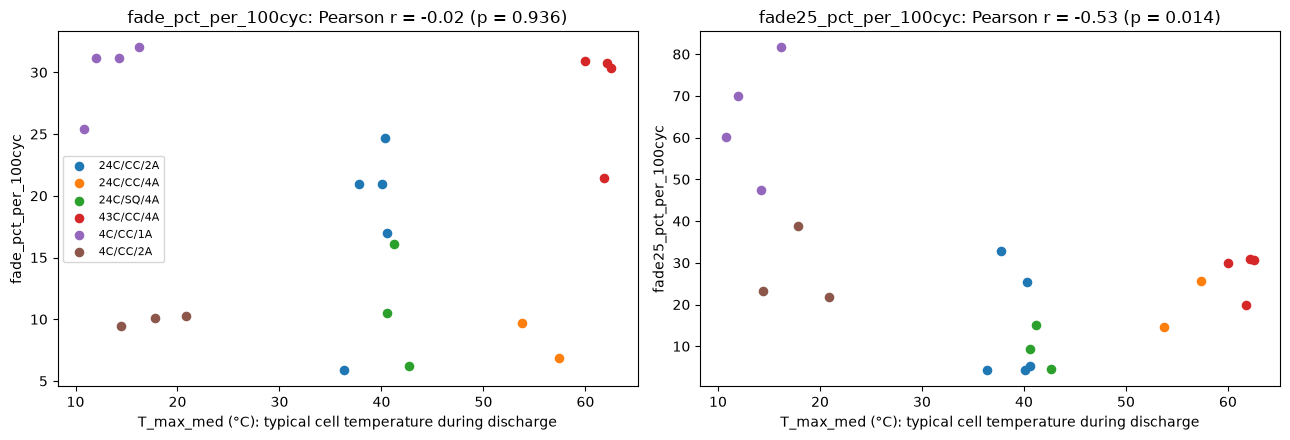

,variable,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,fade_pct_per_100cyc,21,-0.0185,0.9365,-0.1065,0.6459
1,fade25_pct_per_100cyc,21,-0.5293,0.0136,-0.3792,0.0900


In [13]:
corr_rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, Y.values()):
    pr = stats.pearsonr(main.T_max_med, main[col])
    sr = stats.spearmanr(main.T_max_med, main[col])
    corr_rows.append({"variable": col, "n": len(main), "pearson_r": pr.statistic, "p_pearson": pr.pvalue,
                      "spearman_rho": sr.statistic, "p_spearman": sr.pvalue})
    for lv in LEVELS:
        d = main[main.condition == lv]
        ax.scatter(d.T_max_med, d[col], label=lv, s=35)
    ax.set_xlabel("T_max_med (°C): typical cell temperature during discharge")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: Pearson r = {pr.statistic:.2f} (p = {pr.pvalue:.3f})")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "inf_03_fade_vs_cell_temp.png", dpi=150)
plt.show()
corr_table = pd.DataFrame(corr_rows)
corr_table.round(4)

The plot shows a **non-monotonic** relation: the fade rate is high at both ends (the coldest cells at 4 °C/1 A and the hottest at 43 °C) and lower in between.
A linear correlation over the whole sample therefore does not measure this relation correctly, and a negative r must **not** be read as "hotter cells fade more slowly".
Comparison within the 4 °C group only (same ambient temperature, different cell temperature):

In [14]:
cold = main[main.ambient_C == 4]
cold_rows = []
for col in Y.values():
    pr = stats.pearsonr(cold.T_max_med, cold[col])
    sr = stats.spearmanr(cold.T_max_med, cold[col])
    cold_rows.append({"subset": "4 °C (G7 + G9)", "variable": col, "n": len(cold), "pearson_r": pr.statistic,
                      "p_pearson": pr.pvalue, "spearman_rho": sr.statistic, "p_spearman": sr.pvalue})
pd.DataFrame(cold_rows).round(4)

,subset,variable,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,4 °C (G7 + G9),fade_pct_per_100cyc,7,-0.5861,0.1667,-0.3214,0.4821
1,4 °C (G7 + G9),fade25_pct_per_100cyc,7,-0.5177,0.2340,-0.5357,0.2152


## 8. Summary table (C2.8)

The table below collects every test of the notebook. It is built automatically from the results above and saved to `reports/tables/inference_summary.csv`.

**Multiple testing.** The table holds 18 tests at the 5% level. Each test answers its own question stated in advance, so the main decision (`decision`) uses the unadjusted p,
but the table also gives the **Holm-adjusted** p over all 18 tests (`p_holm`, `decision_holm`) so the reader can see which results survive a family-wise correction.
Tukey HSD (section 4) already adjusts within its own family of pairwise comparisons. The practical meaning is discussed in section 9.

In [15]:
def decide(p):
    return "reject H0" if p < ALPHA else "do not reject H0"


summary = []
for r in t_table.itertuples():
    summary.append({"test": r.test, "variable": r.variable, "H0": f"μ({r.comparison.split(': ')[1].split(' vs ')[0]}) "
                    f"{'≤' if r.Ha == 'greater' else '='} μ({r.comparison.split(' vs ')[1]})",
                    "method": f"{r.t_test} t-test, {'one-sided' if r.Ha == 'greater' else 'two-sided'}",
                    "statistic": f"T = {r.T:.3f}", "df": round(r.df, 2), "p": r.p, "decision": decide(r.p)})
for a in assumptions.itertuples():
    tab = anova_out[a.variable][0]
    summary.append({"test": "ANOVA", "variable": a.variable, "H0": "the 6 condition groups have equal means",
                    "method": "one-way ANOVA", "statistic": f"F = {a.F:.3f}", "df": f"({int(tab.df[0])},{int(tab.df[1])})",
                    "p": a.p_ANOVA, "decision": decide(a.p_ANOVA)})
    summary.append({"test": "Kruskal-Wallis", "variable": a.variable, "H0": "the 6 condition groups have the same distribution",
                    "method": "non-parametric", "statistic": f"H = {a.H_Kruskal:.3f}", "df": int(tab.df[0]),
                    "p": a.p_Kruskal, "decision": decide(a.p_Kruskal)})
for c in chi_table.itertuples():
    summary.append({"test": f"Chi-square (W = {c.window})", "variable": f"SOH < 0.9 within {c.window} cycles ({c.n_cells} batteries)",
                    "H0": "temperature group is independent of the outcome", "method": "χ² + permutation (since E_ij < 5)",
                    "statistic": f"χ² = {c.chi2:.3f}", "df": c.df, "p": c.p_perm, "decision": decide(c.p_perm)})
for c in corr_table.itertuples():
    summary.append({"test": "Pearson", "variable": c.variable, "H0": "ρ(T_max_med, fade) = 0 (21 batteries)",
                    "method": "t-test of r", "statistic": f"r = {c.pearson_r:.3f}", "df": c.n - 2, "p": c.p_pearson,
                    "decision": decide(c.p_pearson)})
summary = pd.DataFrame(summary)
summary["p_holm"] = multipletests(summary.p, alpha=ALPHA, method="holm")[1]
summary["decision_holm"] = summary.p_holm.map(decide)
summary.to_csv(TAB / "inference_summary.csv", index=False)
t_table.to_csv(TAB / "inference_ttests.csv", index=False)
ci_table.to_csv(TAB / "inference_ci.csv", index=False)
print(f"{len(summary)} tests; rejected at 5%: {int((summary.p < ALPHA).sum())} unadjusted, "
      f"{int((summary.p_holm < ALPHA).sum())} after Holm")
summary.assign(p=summary.p.round(4), p_holm=summary.p_holm.round(4))

18 tests; rejected at 5%: 10 unadjusted, 5 after Holm


,test,variable,H0,method,statistic,df,p,decision,p_holm,decision_holm
0,T1,fade_pct_per_100cyc,μ(43 °C) ≤ μ(24 °C),"pooled t-test, one-sided",T = 5.603,4.0,0.0025,reject H0,0.0349,reject H0
1,T2,fade_pct_per_100cyc,μ(24 °C) = μ(4 °C),"Welch t-test, two-sided",T = 2.440,4.04,0.0706,do not reject H0,0.5645,do not reject H0
2,T3,fade_pct_per_100cyc,μ(1 A) = μ(2 A),"Welch t-test, two-sided",T = 13.017,3.15,0.0008,reject H0,0.0123,reject H0
3,T4,fade_pct_per_100cyc,μ(square wave) = μ(CC),"pooled t-test, two-sided",T = 0.695,3.0,0.5369,do not reject H0,1.0000,do not reject H0
4,T2b (G1 only),fade_pct_per_100cyc,μ(G1 only) = μ(4 °C),"Welch t-test, two-sided",T = 6.886,3.14,0.0054,reject H0,0.0706,do not reject H0
5,T1,fade25_pct_per_100cyc,μ(43 °C) ≤ μ(24 °C),"pooled t-test, one-sided",T = 1.495,4.0,0.1046,do not reject H0,0.7322,do not reject H0
6,T2,fade25_pct_per_100cyc,μ(24 °C) = μ(4 °C),"pooled t-test, two-sided",T = -1.485,6.0,0.1881,do not reject H0,0.9852,do not reject H0
7,T3,fade25_pct_per_100cyc,μ(1 A) = μ(2 A),"pooled t-test, two-sided",T = 3.773,5.0,0.0130,reject H0,0.1429,do not reject H0
8,T4,fade25_pct_per_100cyc,μ(square wave) = μ(CC),"pooled t-test, two-sided",T = -1.833,3.0,0.1642,do not reject H0,0.9852,do not reject H0
9,T2b (G1 only),fade25_pct_per_100cyc,μ(G1 only) = μ(4 °C),"pooled t-test, two-sided",T = -1.135,5.0,0.3080,do not reject H0,1.0000,do not reject H0


## 9. Conclusions and practical meaning (C2.8, for Report §5.2)

The numbers below are read from the tables in sections 2–8. "fade" = `fade_pct_per_100cyc` (whole series), "fade25" = `fade25_pct_per_100cyc` (first 25 cycles).
p-values are unadjusted unless marked "Holm" (section 8).

| Test | Result | Robust across both variables? | Practical meaning |
|---|---|---|---|
| CI by group (2.1) | Very wide intervals when n is small. E.g. 24 °C/CC 4 A (n = 2): fade 8.3, CI from −10.0 to 26.5 | – | 21 batteries are too few to quantify the fade rate of each condition precisely. Any number used for warranty terms needs more data. |
| CI of the regeneration share (2.2) | 28.6% of discharges have higher capacity than the previous one (z: 26.6–30.6%). Per battery: 26.7% (t: 22.3–31.1%) | – | Measured capacity fluctuates noticeably between discharges. A battery should not be judged to "improve" from one measurement; smooth it or look at the trend over many cycles. |
| T1: 43 °C > 24 °C at 4 A | fade: reject H0 (p = 0.0025; Holm 0.035). fade25: do not reject (p = 0.105), although in the same direction (27.8 vs 20.1) | **No** | The whole-series result is biased: G3 only runs 39 cycles while B0033/B0034 run about 190 cycles with a flattening phase that pulls the slope down. On the fair window (fade25) the direction is as expected but the evidence is not enough with 4 and 2 batteries. Thermal management remains a sensible recommendation, but it rests on the known mechanism more than on this data. |
| T2: 24 °C vs 4 °C at 2 A | Do not reject for either variable (p = 0.071 and 0.188), and the **direction flips**: fade says 24 °C fades faster (T = 2.44), fade25 says 4 °C fades faster (T = −1.49). G1-only version (T2b): fade rejects (p = 0.0054; Holm 0.071), fade25 does not | **No** | The conclusion depends on how fade is measured and on whether B0036 (fade 5.9, much lower than G1) is pooled. There is no basis to say whether 24 °C or 4 °C is worse at 2 A. |
| T3: 1 A vs 2 A at 4 °C | Reject for both variables: fade difference 20.0 (CI 15.2–24.7; p = 0.0008; Holm 0.012), fade25 difference 36.8 (CI 11.7–61.9; p = 0.013; Holm 0.143) | **Yes** (unadjusted) | The most robust result: at 4 °C, discharging at a low 1 A makes the battery fade **faster** than at 2 A. Counter-intuitive; a plausible explanation is that 2 A self-heats the cell (section 7). For fleets in cold regions: warm the battery before light-load operation, and warranty terms should account for cold climates. The fade25 result does not survive the Holm correction, so it should be reported as supporting, not confirmatory. |
| T4: square wave vs CC at 24 °C/4 A | Do not reject for either variable (p = 0.537 and 0.164) | Yes (no difference in both) | No evidence that a 0.05 Hz pulsed load ages the battery faster than a constant load of the same amplitude. No need to split warranty terms by load profile yet. |
| ANOVA, 6 condition groups | Reject for both variables (F = 12.69 and 12.67; p = 0.0001; Holm 0.001). Levene does not reject. Shapiro rejects for fade (p = 0.042), but Kruskal-Wallis still rejects (p = 0.008 and 0.022; Holm 0.099 and 0.200) | **Yes** | Operating condition really affects the fade rate. Tukey: 4 °C/1 A differs from most groups for both variables. For fade, 43 °C/4 A also differs from 24 °C/CC 4 A, 24 °C/square wave and 4 °C/2 A; for fade25, 43 °C/4 A only differs from 4 °C/1 A. |
| Two-way ANOVA | Not possible: 4/9 cells empty | – | The temperature × current interaction cannot be separated. The next test campaign should use a full factorial design. |
| Chi-square | W = 25: reject (χ² = 13.09; permutation p = 0.0014; Holm 0.021). W = 39: do not reject (permutation p = 0.319) | **No** | Batteries at 4 °C drop below 0.9 much earlier within the first 25 cycles, but by about 39 cycles batteries at all three temperatures have many below 0.9. Cold makes capacity drop **earlier**, not necessarily more in the long run. Both windows must be reported (the change from W = 40 awaits the Leader's sign-off). |
| Correlation with cell temperature | fade: r = −0.02 (p = 0.94). fade25: r = −0.53 (p = 0.014; Holm 0.143). Within the 4 °C group only (n = 7): r negative but not significant | **No** | The relation is not monotonic (both the cold and the hot end are bad), so the negative r must not be read as "hotter cells fade more slowly". The hypothesis "cell temperature matters more than ambient temperature" is only supported in direction; more batteries are needed to test it. |

**General remarks:**
- **The conclusion about temperature depends on how the fade rate is measured; the conclusion about discharge current at 4 °C is robust.** Only T3 rejects H0 for both variables;
  T1 and T2 change decision (and T2 even changes direction) between fade and fade25. This is what Introduction_of_dataset.md section 8 anticipated.
- **Multiple testing:** 10 of the 18 tests reject H0 at 5% unadjusted; 5 still do after the Holm correction (T1 fade, T3 fade, both ANOVAs, chi-square W = 25).
  Each test answers its own pre-stated question, so the main decisions use unadjusted p, and the Holm column is reported alongside them.
- In T2 and T3 the F-test rejects equal variances while Levene does not, because the 4 °C/2 A group has a very small standard deviation (0.41). Following the pre-defined procedure,
  the decision uses the F-test (slides), so these pairs use Welch.
- With n = 2 in one group (T1, T4), the F-test and Levene have almost no power, so "equal variances not rejected" does not mean the variances are equal. The Welch p-value
  (`p_Welch` in `inference_ttests.csv`) gives the same decision as the pre-defined test in all 10 rows.
- With 2 to 5 batteries per group, the power of every test is very low. "Do not reject H0" here means "not enough evidence", **not** "no difference".
- The two fade measures disagree for T1, T2, the chi-square and the correlation. The report must present both.
- This notebook uses 21 batteries; the battery-level regression (Quốc Đạt) uses 23 (with B0054 and B0028). The report must state the sample used for each result.

**Outputs:**
- Tables: `reports/tables/inference_summary.csv` (summary, with Holm-adjusted p), `inference_ttests.csv` (T1–T4 details, with the Welch sensitivity check), `inference_ci.csv` (CI by group).
- Figures: `reports/figures/inf_01_ci_by_condition.png`, `inf_02_anova_qq.png`, `inf_03_fade_vs_cell_temp.png`.